<center><h1>Blombach_George_HW8</h1></center>

Name: George Blombach | Github Username: gblombach | USC ID: 2416-0961-99

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

Import packages

In [34]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, \
    f1_score, roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

### (a) Download the Breast Cancer Wisconsin (Diagnostic) Data Set

In [79]:
#569 instance, 32 total attributes; diagnosis: 357 Benign, 212 Malignant
raw_data = pd.read_csv("../data/wdbc.data", header = None)
#display(raw_data.shape)
mapping = {'M':1, 'B':0}                      #define Malignant/Benign to 1/0 mapping
data = raw_data.copy()
data.columns = ["ID","Diagnosis"] + [f'attr{i}' for i in range(1,31)]
data['Diagnosis'] = data['Diagnosis'].map(mapping) # replace M/B with 1/0 
#print(raw_data.head())
#print(data.head())

### (b) Monte-Carlo Simulation

In [80]:
#print(data.columns.tolist())

In [89]:
# setup data
y = data['Diagnosis'].copy()
X = data.drop(columns=['ID','Diagnosis']).copy()
M = 30 #number of monte carlo simulations
C_grid = np.logspace(-4, 4, 9) #Candidate penalty parameters for  L1-penalized SVM
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
results = []
representative_simulation = {}

# Function for deriving metrics
def calc_metrics(y_true, y_pred, scores):
    return {"Accuracy": accuracy_score(y_true, y_pred), 
            "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
            "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
            "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
            "AUC": roc_auc_score(y_true, scores)}

# Function for recording results
def log_results(results, run, method, split, y_true, y_pred, scores):
    results.append({"run": run + 1,"method": method, "split": split, 
                    **calc_metrics( y_true, y_pred, scores)})

# Function for ROC and Confusion Matrix
def show_roc_and_cm(y_train, y_test, train_pred, test_pred, train_scores, test_scores, method):
    fig, axes = plt.subplots(nrows=1,ncols=4,figsize=(20, 4))
    ConfusionMatrixDisplay.from_predictions(y_train, train_pred, labels=[0, 1], display_labels=["Benign", "Malignant"], cmap="Blues", colorbar=False, ax=axes[0])
    ConfusionMatrixDisplay.from_predictions(y_test, test_pred, labels=[0, 1], display_labels=["Benign", "Malignant"], cmap="Blues", colorbar=False, ax=axes[1])
    axes[0].set_title(f"{method}: Training", fontsize=12)
    axes[1].set_title(f"{method}: Testing", fontsize=12)
    fpr, tpr, _ = roc_curve(y_train, train_scores)                   #ROC 
    train_auc = roc_auc_score(y_train, train_scores)
    axes[2].plot(fpr, tpr, linewidth=2, label=f"AUC = {train_auc:.3f}")
    axes[2].plot([0, 1], [0, 1],linestyle=":", color="black", alpha=0.6)
    axes[2].set_title(f"{method}: Training ROC", fontsize=12)
    axes[2].set_xlabel("False Positive Rate")
    axes[2].set_ylabel("True Positive Rate")
    axes[2].legend(fontsize=8)
    fpr, tpr, _ = roc_curve(y_test, test_scores)
    test_auc = roc_auc_score(y_test, test_scores)
    axes[3].plot(fpr, tpr, linewidth=2, label=f"AUC = {test_auc:.3f}")
    axes[3].plot([0, 1], [0, 1], linestyle=":", color="black", alpha=0.6)
    axes[3].set_title(f"{method}: Testing ROC", fontsize=12)
    axes[3].set_xlabel("False Positive Rate", fontsize=10)
    axes[3].set_ylabel("True Positive Rate", fontsize=10)
    axes[3].legend(fontsize=8)
    for ax in axes:
        ax.tick_params(axis="both", labelsize=8)
    plt.tight_layout()
    plt.show()

#### (i) Supervised Learning

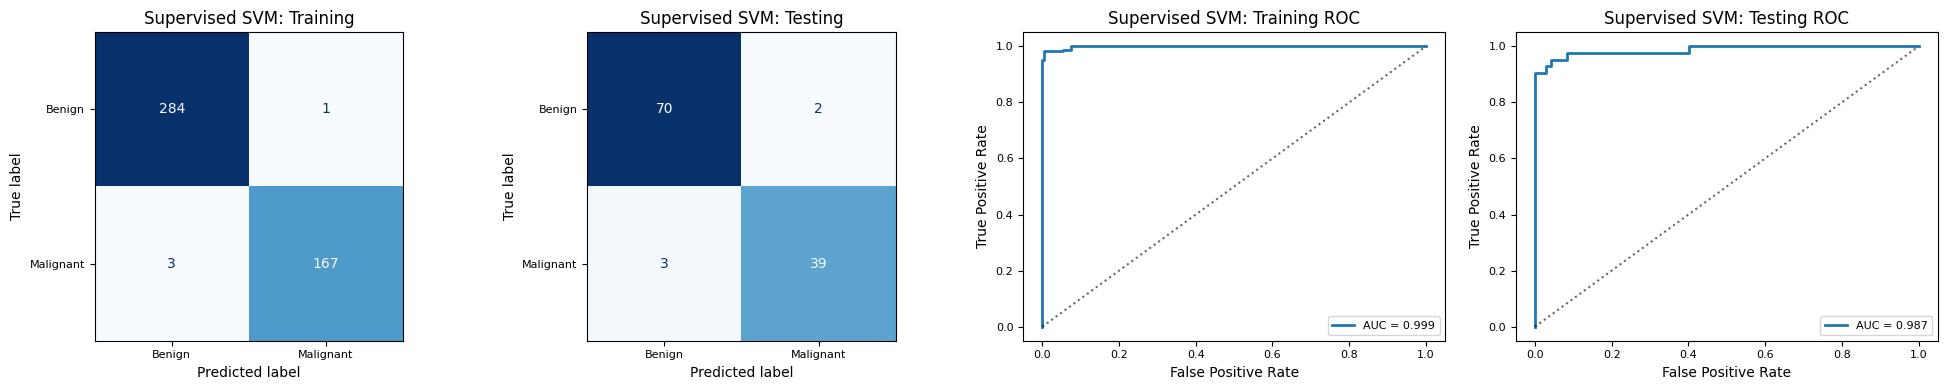

In [77]:
# Function for 5 fold cross validation  
def fit_l1_svm(X_train, y_train, random_state):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state)
    pipeline = Pipeline([("scaler", StandardScaler()), ("svm", LinearSVC(penalty="l1", dual=False,
            max_iter=10000, tol=1e-3, random_state=random_state))])
    grid_search = GridSearchCV(estimator=pipeline, param_grid={"svm__C": C_grid},  scoring="accuracy", cv=cv, n_jobs=-1)
    grid_search.fit(X_train, y_train)
    return (grid_search.best_estimator_)
    
# perform representive run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=333)
supervised_model = fit_l1_svm(X_train, y_train, random_state=333)
supervised_train_pred = supervised_model.predict(X_train)
supervised_test_pred = supervised_model.predict(X_test)
supervised_train_scores = (supervised_model.decision_function(X_train))
supervised_test_scores = (supervised_model.decision_function(X_test))

# show ROC and confusion matrix for representative run
show_roc_and_cm(y_train, y_test, supervised_train_pred, supervised_test_pred, supervised_train_scores,supervised_test_scores , "Supervised SVM")   

In [ ]:
#Run all
#for simulation in range(M):              #iterate monte-carlo simulations, stratify data 20%, split test and train
#    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=simulation)
#    supervised_model, supervised_C = tune_l1_svm(X_train, y_train, random_state=run)      #supervised L1-penalized

#### (ii) Semi-Supervised Learning/ Self-training

In [ ]:
semi_train_results = []
semi_test_results = []
semi_best_C = []

##### (A)

In [85]:
def fit_self_l1_svm(X_labeled, y_labeled, X_unlabeled,  random_state):
    initial_model = fit_l1_svm(X_labeled, y_labeled,  random_state)  # Choose C using 5-fold CV on the initial labeled set
    best_C = initial_model.named_steps["svm"].C
    # Final self-training pipeline using the selected C
    model = Pipeline([("scaler", StandardScaler()),("svm", LinearSVC(penalty="l1", dual=False, C=best_C, max_iter=10000,
                tol=1e-3, random_state=random_state))])
    X_labeled = X_labeled.copy().reset_index(drop=True)
    y_labeled = y_labeled.copy().reset_index(drop=True)
    X_unlabeled = X_unlabeled.copy().reset_index(drop=True)
    while len(X_unlabeled) > 0:
        model.fit(X_labeled, y_labeled)                           # Retrain using the current labeled set
        unlabeled_scores = model.decision_function(X_unlabeled)   # Find the distance of every unlabeled observation
                                                                  # from the SVM decision boundary
        farthest_idx = np.argmax(np.abs(unlabeled_scores))        # The largest absolute score is farthest from
        selected_point = X_unlabeled.iloc[[farthest_idx]]         # the decision boundary
        pseudo_label = model.predict(selected_point)[0]           # Use the SVM's prediction, not the true label
        X_labeled = pd.concat([X_labeled, selected_point],ignore_index=True)   # Add the selected point and pseudo-label
        y_labeled = pd.concat([y_labeled, pd.Series([pseudo_label], name=y_labeled.name)],ignore_index=True)
        X_unlabeled = (X_unlabeled.drop(X_unlabeled.index[farthest_idx]).reset_index(drop=True)) # remove the point
    model.fit(X_labeled, y_labeled)                               # Final fit after all unlabeled observations are added
    return model

#function to split data
def split_labeled_unlabeled(X_train, y_train, random_state):
    rng = np.random.default_rng(random_state)
    X_train = X_train.reset_index(drop=True)                      # Reset indices so positions align
    y_train = y_train.reset_index(drop=True)
    positive_idx = np.where(y_train.to_numpy() == 1)[0]
    negative_idx = np.where(y_train.to_numpy() == 0)[0]           # Randomly select 50% of each class as labeled
    labeled_positive_idx = rng.choice(positive_idx,size=len(positive_idx) // 2, replace=False)
    labeled_negative_idx = rng.choice(negative_idx,size=len(negative_idx) // 2, replace=False)
    labeled_idx = np.concatenate([labeled_positive_idx, labeled_negative_idx])
    rng.shuffle(labeled_idx)
    unlabeled_idx = np.setdiff1d(np.arange(len(X_train)), labeled_idx)
    X_labeled = (X_train.iloc[labeled_idx].reset_index(drop=True))
    y_labeled = (y_train.iloc[labeled_idx].reset_index(drop=True))
    X_unlabeled = (X_train.iloc[unlabeled_idx].reset_index(drop=True))

    return X_labeled, y_labeled, X_unlabeled

##### (B)

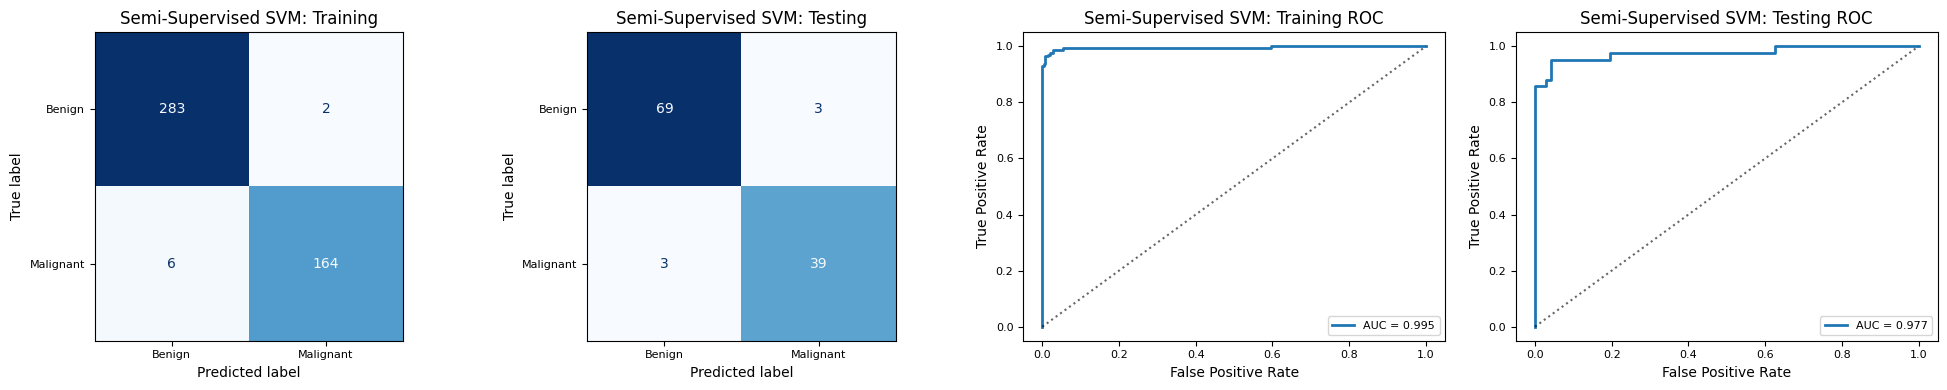

In [90]:
# Perform representative run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=333)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)                        # Select 50% of each training class as labeled
X_labeled, y_labeled, X_unlabeled = (split_labeled_unlabeled(X_train, y_train, random_state=333))
semi_supervised_model = fit_self_l1_svm(X_labeled,y_labeled, X_unlabeled, random_state=333)
semi_train_pred = semi_supervised_model.predict(X_train)                #training prediction
semi_train_scores = (semi_supervised_model.decision_function(X_train))  #training scores
semi_test_pred = semi_supervised_model.predict(X_test)                  #testing predictions 
semi_test_scores = (semi_supervised_model.decision_function(X_test))    #testing decision scores
# show results
show_roc_and_cm(y_train, y_test,semi_train_pred,semi_test_pred, semi_train_scores,semi_test_scores,"Semi-Supervised SVM")

#### (iii) Unsupervised Learning

##### (A)

##### (B)

#### (iv) Spectral Clustering

#### (iv) Compare

## 2. Active Learning Using Support Vector Machines

### (a) Download the banknote authentication Data Set

### (b) Repeat each of the following two procedures 50 times

#### (i) Passive

#### (ii) Active

### (c) Average the 50 test errors